# Object Recognition: YOLOv3 + OpenCV (Google Colab)

## 1. Setup

In [1]:
import subprocess
import sys


def has_darknet_support():
    probe = subprocess.run(
        [sys.executable, '-c',
         'import cv2; print("OpenCV", cv2.__version__); '
         'assert hasattr(cv2.dnn, "readNetFromDarknet"), "Darknet DNN missing"'],
        capture_output=True, text=True,
    )
    print((probe.stdout + probe.stderr).strip())
    return probe.returncode == 0


if not has_darknet_support():
    print('Memperbaiki instalasi OpenCV tanpa mengganti YOLOv3...')
    subprocess.run(
        [sys.executable, '-m', 'pip', 'uninstall', '-y',
         'opencv-python', 'opencv-python-headless',
         'opencv-contrib-python', 'opencv-contrib-python-headless'],
        check=True,
    )
    subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q', '--no-deps',
         'opencv-python-headless==4.11.0.86'],
        check=True,
    )
    if not has_darknet_support():
        raise RuntimeError('Instalasi OpenCV gagal. Periksa log pip di atas.')
    if 'cv2' in sys.modules:
        raise RuntimeError(
            'OpenCV sudah diperbaiki, tetapi versi lama masih tersimpan di memori. '
            'Pilih Runtime > Restart session, lalu Run all dari awal (cukup sekali).'
        )

import cv2
assert hasattr(cv2.dnn, 'readNetFromDarknet'), 'Darknet API tidak tersedia'
print(f'OpenCV {cv2.__version__} siap untuk YOLOv3')


OpenCV 5.0.0
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import cv2; print("OpenCV", cv2.__version__); assert hasattr(cv2.dnn, "readNetFromDarknet"), "Darknet DNN missing"
                                                         ~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: Darknet DNN missing
Memperbaiki instalasi OpenCV tanpa mengganti YOLOv3...
OpenCV 4.11.0
OpenCV 4.11.0 siap untuk YOLOv3


In [2]:
import hashlib
import os
import subprocess
import time
from base64 import b64encode
from pathlib import Path

import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow
from IPython.display import HTML, display

ROOT = Path("/content/YoloObjectDetection")
MODEL_DIR = ROOT / "yolo-coco"
IMAGE_DIR = ROOT / "images"
VIDEO_DIR = ROOT / "videos"
OUTPUT_DIR = ROOT / "output"

for folder in (MODEL_DIR, IMAGE_DIR, VIDEO_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

os.chdir(ROOT)

WEIGHTS_BYTES = 248007048
WEIGHTS_SHA256 = "523e4e69e1d015393a1b0a441cef1d9c7659e3eb2d7e15f793f060a21b32f297"

ASSETS = {
    "coco.names": (
        ["https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names"],
        None,
    ),
    "yolov3.cfg": (
        ["https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3.cfg"],
        None,
    ),
    "yolov3.weights": (
        [
            "https://pjreddie.com/media/files/yolov3.weights",
            "https://huggingface.co/spaces/Senasu/Count_Object_In_Image/resolve/main/yolov3.weights",
            "https://huggingface.co/spaces/oussamamatar/yolo-mediapipe/resolve/main/yolov3.weights",
        ],
        WEIGHTS_BYTES,
    ),
}


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def fetch(dest, urls, size=None):
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0 and (size is None or dest.stat().st_size == size):
        print(f"cached  {dest.name}")
        return
    for url in urls:
        run = subprocess.run(["wget", "-q", "--tries=2", "--timeout=30", "-O", str(dest), url])
        valid = run.returncode == 0 and dest.exists() and dest.stat().st_size > 0
        if valid and (size is None or dest.stat().st_size == size):
            print(f"ok      {dest.name} <- {url}")
            return
        dest.unlink(missing_ok=True)
    raise RuntimeError(
        f"Semua mirror gagal untuk {dest.name}. Upload manual lewat files.upload() ke {dest.parent}"
    )


def upload_to(folder):
    for name, data in files.upload().items():
        (Path(folder) / name).write_bytes(data)


for name, (urls, size) in ASSETS.items():
    fetch(MODEL_DIR / name, urls, size)

print("weights sha256 match:", sha256_of(MODEL_DIR / "yolov3.weights") == WEIGHTS_SHA256)

ok      coco.names <- https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names
ok      yolov3.cfg <- https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3.cfg
ok      yolov3.weights <- https://pjreddie.com/media/files/yolov3.weights
weights sha256 match: True


## 2. Code `yolo.py`


In [3]:
from functools import lru_cache


@lru_cache(maxsize=1)
def load_yolov3(yolo_dir):
    model_dir = Path(yolo_dir)
    names_path = model_dir / 'coco.names'
    cfg_path = model_dir / 'yolov3.cfg'
    weights_path = model_dir / 'yolov3.weights'
    for path in (names_path, cfg_path, weights_path):
        if not path.is_file():
            raise FileNotFoundError(f'File model YOLOv3 tidak ditemukan: {path}')

    labels = names_path.read_text().strip().splitlines()
    rng = np.random.default_rng(42)
    colors = rng.integers(0, 255, size=(len(labels), 3), dtype=np.uint8)

    print('[INFO] Loading YOLOv3 dari yolov3.cfg + yolov3.weights...')
    net = cv2.dnn.readNetFromDarknet(str(cfg_path), str(weights_path))
    layer_names = net.getUnconnectedOutLayersNames()
    return net, labels, colors, layer_names


def predict_top1_yolov3(frame, net, labels, colors, layer_names,
                        confidence_threshold=0.5, nms_threshold=0.3):
    H, W = frame.shape[:2]
    blob = cv2.dnn.blobFromImage(
        frame, scalefactor=1 / 255.0, size=(416, 416),
        swapRB=True, crop=False,
    )
    net.setInput(blob)
    layer_outputs = net.forward(layer_names)

    boxes, confidences, class_ids = [], [], []
    for output in layer_outputs:
        for detection in output:
            scores = detection[5:]
            class_id = int(np.argmax(scores))
            confidence = float(scores[class_id])
            if not np.isfinite(confidence) or confidence < confidence_threshold:
                continue

            center_x, center_y, width, height = (
                detection[:4] * np.array([W, H, W, H])
            ).astype(int)
            x1 = max(0, int(center_x - width / 2))
            y1 = max(0, int(center_y - height / 2))
            x2 = min(W - 1, int(center_x + width / 2))
            y2 = min(H - 1, int(center_y + height / 2))
            if x2 <= x1 or y2 <= y1:
                continue
            boxes.append([x1, y1, x2 - x1, y2 - y1])
            confidences.append(confidence)
            class_ids.append(class_id)

    if not boxes:
        return None
    keep = cv2.dnn.NMSBoxes(
        boxes, confidences, confidence_threshold, nms_threshold
    )
    if len(keep) == 0:
        return None
    i = max(np.asarray(keep).reshape(-1).tolist(), key=lambda j: confidences[j])
    return {
        'label': labels[class_ids[i]],
        'confidence': confidences[i],
        'box': boxes[i],
        'color': [int(c) for c in colors[class_ids[i]]],
    }


def draw_top1(frame, prediction):
    if prediction is None:
        return frame
    x, y, w, h = prediction['box']
    color = prediction['color']
    cv2.rectangle(frame, (x, y), (x + w, y + h), color, 2)
    text = f"{prediction['label']}: {prediction['confidence']:.4f}"
    cv2.putText(frame, text, (x, max(15, y - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    return frame


def yolo_image(args):
    image = cv2.imread(args['image'])
    if image is None:
        raise FileNotFoundError(f"Gambar tidak dapat dibaca: {args['image']}")
    net, labels, colors, layer_names = load_yolov3(args['yolo'])

    start = time.time()
    prediction = predict_top1_yolov3(
        image, net, labels, colors, layer_names,
        args.get('confidence', 0.5), args.get('threshold', 0.3),
    )
    print('[INFO] YOLOv3 took {:.3f} seconds'.format(time.time() - start))
    if prediction:
        print(f"[TOP-1] {prediction['label']} ({prediction['confidence']:.2%})")
    else:
        print('[TOP-1] Tidak ada objek di atas confidence threshold')
    draw_top1(image, prediction)
    cv2_imshow(image)
    return image


## 3. Practice 1: Gambar (maksimal 1 prediksi per gambar)

Upload gambar dari class berbeda di `coco.names`. Setiap gambar mendapat **satu bounding box dengan confidence tertinggi setelah NMS**, bukan semua deteksi. Jika tidak ada confidence yang melewati threshold, tidak ada bounding box.


In [4]:
upload_to(IMAGE_DIR)
print(sorted(p.name for p in IMAGE_DIR.iterdir()))

Saving Apel.jpg to Apel.jpg
['Apel.jpg']



(Yolo) python yolo.py --image images/Apel.jpg --yolo yolo-coco
[INFO] Loading YOLOv3 dari yolov3.cfg + yolov3.weights...
[INFO] YOLOv3 took 6.342 seconds
[TOP-1] apple (88.95%)


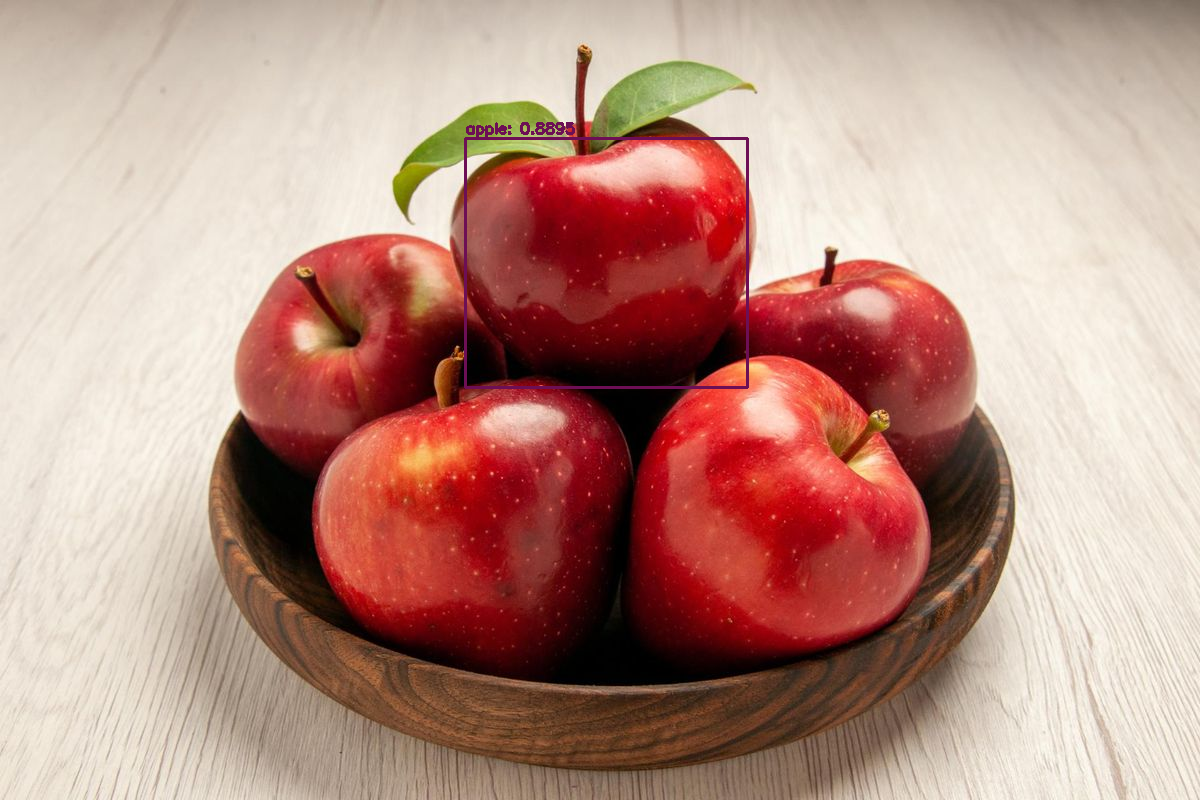

In [5]:
IMAGE_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

for path in sorted(p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in IMAGE_EXT):
    args = {
        "image": f"images/{path.name}",
        "yolo": "yolo-coco",
        "confidence": 0.5,
        "threshold": 0.3,
    }
    print(f"\n(Yolo) python yolo.py --image {args['image']} --yolo {args['yolo']}")
    result = yolo_image(args)
    cv2.imwrite(f"output/{path.stem}_yolo.jpg", result)

## 4.`yolo_video.py`



In [6]:
def yolo_video(args):
    """Video YOLOv3: hanya satu prediksi terbaik di setiap frame."""
    net, labels, colors, layer_names = load_yolov3(args['yolo'])
    vs = cv2.VideoCapture(args['input'])
    if not vs.isOpened():
        raise FileNotFoundError(f"Video tidak dapat dibuka: {args['input']}")

    total = int(vs.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(vs.get(cv2.CAP_PROP_FPS))
    if not np.isfinite(fps) or fps <= 0:
        fps = 30.0
    print(f'[INFO] Total frame: {total if total > 0 else "tidak diketahui"}')

    writer = None
    processed = 0
    top_labels = {}  # satu ringkasan kelas dominan untuk keseluruhan video
    try:
        while True:
            grabbed, frame = vs.read()
            if not grabbed:
                break

            prediction = predict_top1_yolov3(
                frame, net, labels, colors, layer_names,
                args.get('confidence', 0.5), args.get('threshold', 0.3),
            )
            if prediction is not None:
                name = prediction['label']
                top_labels[name] = top_labels.get(name, 0) + 1
            draw_top1(frame, prediction)

            if writer is None:
                height, width = frame.shape[:2]
                writer = cv2.VideoWriter(
                    args['output'], cv2.VideoWriter_fourcc(*'MJPG'),
                    fps, (width, height), True,
                )
                if not writer.isOpened():
                    raise RuntimeError(f"Tidak bisa menyimpan video: {args['output']}")
            writer.write(frame)
            processed += 1
    finally:
        vs.release()
        if writer is not None:
            writer.release()

    if processed == 0:
        raise ValueError(f"Tidak ada frame valid di video: {args['input']}")
    if top_labels:
        dominant = max(top_labels, key=top_labels.get)
        print(f'[TOP-1 VIDEO] {dominant} (terdeteksi di {top_labels[dominant]}/{processed} frame)')
    else:
        print('[TOP-1 VIDEO] Tidak ada objek di atas confidence threshold')
    print(f'[INFO] Video tersimpan: {args["output"]}')


## 5. Practice 2: Video (maksimal 1 prediksi per frame)

Upload video pendek. **YOLOv3 tetap sama**; setiap frame akan diberi maksimal **satu bounding box**. Setelah video selesai, dicetak satu ringkasan label yang paling sering menjadi prediksi top-1.

Cell trim di bawah opsional: memotong input video ke beberapa detik pertama.


In [7]:
upload_to(VIDEO_DIR)
print(sorted(p.name for p in VIDEO_DIR.iterdir()))

Saving overpass.mp4 to overpass.mp4
['overpass.mp4']


In [8]:
TRIM_SECONDS = 10
VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv", ".webm"}


def trim(src, dst, seconds):
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", str(src), "-t", str(seconds), "-c:v", "libx264", "-an", str(dst)],
        check=True,
    )


for path in sorted(p for p in VIDEO_DIR.iterdir() if p.suffix.lower() in VIDEO_EXT and not p.stem.endswith("_trim")):
    trim(path, VIDEO_DIR / f"{path.stem}_trim.mp4", TRIM_SECONDS)
    print("trimmed:", path.name)

trimmed: overpass.mp4


In [ ]:
def to_mp4(avi):
    mp4 = Path(avi).with_suffix(".mp4")
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", str(avi), "-vcodec", "libx264", "-pix_fmt", "yuv420p", str(mp4)],
        check=True,
    )
    return mp4


def show_video(path, width=720):
    payload = b64encode(Path(path).read_bytes()).decode()
    return HTML(
        f'<video width="{width}" controls><source src="data:video/mp4;base64,{payload}" type="video/mp4"></video>'
    )


video_outputs = []
for path in sorted(VIDEO_DIR.glob("*_trim.mp4")):
    name = path.stem.removesuffix("_trim")
    args = {
        "input": f"videos/{path.name}",
        "output": f"output/{name}_output.avi",
        "yolo": "yolo-coco",
        "confidence": 0.5,
        "threshold": 0.3,
    }
    print(f"\n(Yolo) python yolo_video.py --input {args['input']} --output {args['output']} --yolo {args['yolo']}")
    yolo_video(args)
    video_outputs.append(to_mp4(args["output"]))


(Yolo) python yolo_video.py --input videos/overpass_trim.mp4 --output output/overpass_output.avi --yolo yolo-coco
[INFO] Total frame: 300


In [ ]:
for mp4 in video_outputs:
    print(mp4.name)
    display(show_video(mp4))

## 6. Download semua hasil

In [ ]:
import shutil

archive = shutil.make_archive("/content/yolo_results", "zip", OUTPUT_DIR)
files.download(archive)